In [118]:
import os
import re
import csv
import pandas as pd

In [119]:
filepath = "1.2_assets/"
files_names = ["01_atendimentos_bagunçados.txt", "02_logs_mistos.log", "03_mensagens_chat.txt", "04_exportacao_suja.csv"]

# 1. QUESTÃO A)

Implemente um módulo capaz de: ler todos os
arquivos fornecidos; contabilizar o número de linhas de cada arquivo; identificar o tipo
geral de conteúdo de cada arquivo (texto livre, log, chat ou CSV); apresentar uma
pequena amostra de conteúdo de cada arquivo.

In [120]:
import re
import pandas as pd


""" Implemente um módulo capaz de: """
class FileReader:
    def __init__(self, filepath):
        self._filepath = filepath
        self.df = self._convert_to_df()

    """
    ler todos os arquivos fornecidos;
    """
    def get_file_name(self) -> str:
        return self._filepath

    def _convert_to_df(self) -> pd.DataFrame:
        file_name_pattern = re.compile(r".+\.([a-z]+)")
        file_type = re.match(file_name_pattern, self._filepath).group(1)
        match file_type:
            case "txt":
                return pd.read_table(self._filepath, header=None, encoding="utf-8")
            case "log":
                return pd.read_table(self._filepath, header=None, encoding="utf-8")
            case "csv":
                return pd.read_csv(self._filepath, sep=';')
            case _:
                raise TypeError('Cannot guess this file type!')

    def check_content_type(self) -> str:
        """
        identificar o tipo geral de conteúdo de cada arquivo\n
        (texto livre, log, chat ou CSV);
        """

        # padrão rápido para validação
        quick_datetime_pattern = re.compile(
            r"(0[1-9]|(1|2)[0-9]|3(0|1))/" # dia
            r"(0[1-9]|1[0-2])/" # mẽs
            r"(199[0-9]|20[0-9][0-9])" # ano
            r"\s+" # espaço
            r"(0[0-9]|1[0-9]|2[0-3]):" # hora
            r"([0-5][0-9]):" # minuto
            r"([0-5][0-9])" # segundo
        )
        log_pattern = re.compile(fr"{quick_datetime_pattern.pattern}\s+(\[(INFO|DEBUG|ERROR|WARN)\])+")
        chat_pattern = re.compile(fr"\[{quick_datetime_pattern.pattern}\]\s+(A|Z)*")
        csv_pattern = re.compile(r"\d+;")

        def detect_type(file_content: str):
            if log_pattern.search(file_content):
                return "log"
            elif chat_pattern.search(file_content):
                return "chat"
            elif csv_pattern.search(file_content):
                return "csv"
            else:
                return "free text"
            
        if self._filepath.endswith(".csv"):
            return "This is a CSV file"

        conteudo_inicial = self.df.iloc[0, 0]

        # previnindo pois em certos ambientes o conteúdo pode chegar como bytes.
        if isinstance(conteudo_inicial, bytes):
            conteudo_inicial = conteudo_inicial.decode("utf-8", errors="ignore")
        else:
            conteudo_inicial = str(conteudo_inicial)

        file_content_type = detect_type(conteudo_inicial)
        return f"This is a {file_content_type} file"
    

    def count_lines(self) -> int:
        """ contabilizar o número de linhas de cada arquivo; """
        return self.df.shape[0]

    def show_sample(self) -> str:
        """ apresentar uma pequena amostra de conteúdo de cada arquivo. """
        return self.df.head()

    def __str__(self):
        return str(self.show_sample())


In [121]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## A) Testando a classe FileReader

In [122]:


filepath = "/content/drive/MyDrive/Automatos regex trab/1.2_assets/"
files_names = ["01_atendimentos_bagunçados.txt", "02_logs_mistos.log", "03_mensagens_chat.txt", "04_exportacao_suja.csv"]

fileReaders = []
for name in files_names:
    caminho = filepath + name
    print("Caminho: ",caminho, "->", "Existe?" , os.path.exists(caminho))

    print(f"Handling file: {filepath+name}\n")
    file = FileReader(filepath=filepath+name)
    print(f"Content type: {file.check_content_type()}")
    print(f"Number of lines: {file.count_lines()}")
    print(f"Sample (head):\n{file.show_sample()}\n")
    fileReaders.append(file)


Caminho:  /content/drive/MyDrive/Automatos regex trab/1.2_assets/01_atendimentos_bagunçados.txt -> Existe? True
Handling file: /content/drive/MyDrive/Automatos regex trab/1.2_assets/01_atendimentos_bagunçados.txt

Content type: This is a free text file
Number of lines: 4575
Sample (head):
                                                   0
0  CHAMADO 00000 >>> falhou id erro contato de Da...
1  CHAMADO 00001 >>> [INFO] session=RcoreogrNwwm ...
2  CHAMADO 00002 >>> LIMPAR duplicado falhou id c...
3  complemento: [INFO] session=FgM0Fmxk754L user=...
4  CHAMADO 00003 >>> 16/01/2025 15:37:21 | acesso...

Caminho:  /content/drive/MyDrive/Automatos regex trab/1.2_assets/02_logs_mistos.log -> Existe? True
Handling file: /content/drive/MyDrive/Automatos regex trab/1.2_assets/02_logs_mistos.log

Content type: This is a log file
Number of lines: 8000
Sample (head):
                                                   0
0  07/09/2021 20:37:27 [INFO] service=appmobile s...
1  27/06/2022 09:48:26 [D

# QUESTÃO B)

Implemente expressões regulares para identificar e extrair, no mínimo, os seguintes padrões:
    - e-mails,
    - telefones,
    - CPFs,
    - datas,
    - horários,
    - datas e horários combinados,
    - URLs,
    - valores monetários em reais,
    - nomes próprios (definir critérios e justificar).

Para cada tipo de padrão, o sistema deve:
    - aplicar a expressão regular aos arquivos;
    - extrair todas as ocorrências encontradas;
    - indicar em qual arquivo ocorreram.

## CPF Validator

In [123]:
# Créditos: https://github.com/rafahlobo/cpfValidator
def isCpfValid(cpf):
    #  If cpf in the Brazilian format is valid, it returns True, otherwise, it returns False.
    # Check if type is str
    if not isinstance(cpf,str):
        return False

    # Remove some unwanted characters
    cpf = re.sub("[^0-9]",'',cpf)

    # Verify if CPF number is equal
    if cpf=='00000000000' or cpf=='11111111111' or cpf=='22222222222' or cpf=='33333333333' or cpf=='44444444444' or cpf=='55555555555' or cpf=='66666666666' or cpf=='77777777777' or cpf=='88888888888' or cpf=='99999999999':
        return False

    # Checks if string has 11 characters
    if len(cpf) != 11:
        return False

    sum = 0
    weight = 10

    """ Calculating the first cpf check digit. """
    for n in range(9):
        sum = sum + int(cpf[n]) * weight

        # Decrement weight
        weight = weight - 1

    verifyingDigit = 11 -  sum % 11

    if verifyingDigit > 9 :
        firstVerifyingDigit = 0
    else:
        firstVerifyingDigit = verifyingDigit

    """ Calculating the second check digit of cpf. """
    sum = 0
    weight = 11
    for n in range(10):
        sum = sum + int(cpf[n]) * weight

        # Decrement weight
        weight = weight - 1

    verifyingDigit = 11 -  sum % 11

    if verifyingDigit > 9 :
        secondVerifyingDigit = 0
    else:
        secondVerifyingDigit = verifyingDigit

    if cpf[-2:] == "%s%s" % (firstVerifyingDigit,secondVerifyingDigit):
        return True
    return False


## REFinder

In [124]:
def matches_to_list(matches):
    return [match.group(0) for match in matches]
    ...

class REFinder:
    def __init__(self):
        pass

    def extract_emails(self, text: str) -> list[str]:
        printable_chars = r"[\!\#\$\%\&\'\*\+\-\/\=\?\^\_\`\{\|\}\~]"
        letters = r"([a-z]|[A-Z])"
        digits = r"[0-9]"
        user_essential = fr"({letters}|{digits}|{printable_chars})"
        domain_essential = fr"({letters}|{digits})"
        pre_final = fr"{domain_essential}+(\-{domain_essential}+)*\."
        final = r"(org|edu|br|com)"
        user = fr"{user_essential}+(\.{user_essential})*"
        domain = fr"{pre_final}+{final}"
        email_pattern = re.compile(fr"{user}\@{domain}")

        matches = re.finditer(pattern=email_pattern, string=text)
        return matches_to_list(matches)

    def extract_phone_numbers(self, text: str) -> list[str]:
        # Regex geral para números de telefone brasileiros (com ou sem DDD, com 8 ou 9 dígitos no final)
        # Exemplos: (11) 98765-4321, 11 9876-5432, 98765-4321, 9876-5432
        phone_pattern = re.compile(
            r'\b(?:\(?\d{2}\)?\s?)?'  # Opcional: (DDD) ou DDD seguido de espaço
            r'(?:9\d{4}|\d{4})'      # 9XXXX ou XXXX
            r'[\-\s]?'               # Opcional: hífen ou espaço
            r'\d{4}\b'               # XXXX final
        )
        matches = re.finditer(pattern=phone_pattern, string=text)
        return matches_to_list(matches)

    def extract_CPFs(self, text: str) -> list[str]:
        cpf_pattern = re.compile(r"[0-9]{11}|[0-9]{3}\.[0-9]{3}\.[0-9]{3}\-[0-9]{2}")
        matches = re.finditer(pattern=cpf_pattern, string=text)
        valid_cpfs = []
        matches = matches_to_list(matches)
        for match in matches:
            if isCpfValid(match):
                valid_cpfs.append(match)
        return valid_cpfs

    def extract_dates(self, text: str) -> list[str]:
        day = r"(0[1-9]|(1|2)[0-9]|3(0|1))"
        month = r"(0[1-9]|1[0-2])"
        year = r"(199[0-9]|20[0-9]{2})" # 1990 - 2099
        date_pattern = re.compile(fr"{day}\/{month}\/{year}")

        matches = re.finditer(pattern=date_pattern, string=text)
        return matches_to_list(matches)

    def extract_time(self, text: str) -> list[str]:
        hours = r"(0[1-9]|1[0-9]|2[0-3])"
        minutes = r"[0-5][0-9]"
        seconds = r"[0-5][0-9]"
        time_pattern = re.compile(fr"{hours}\:{minutes}\:{seconds}")

        matches = re.finditer(pattern=time_pattern, string=text)
        return matches_to_list(matches)

    def extract_datetime(self, text: str) -> list[str]:
        # Combinação de padrões de data e hora
        day = r"(0[1-9]|(1|2)[0-9]|3(0|1))"
        month = r"(0[1-9]|1[0-2])"
        year = r"(199[0-9]|20[0-9]{2})" # 1990 - 2099
        hours = r"(0[1-9]|1[0-9]|2[0-3])"
        minutes = r"[0-5][0-9]"
        seconds = r"[0-5][0-9]"
        datetime_pattern = re.compile(fr"{day}\/{month}\/{year}\s+{hours}\:{minutes}\:{seconds}")

        matches = re.finditer(pattern=datetime_pattern, string=text)
        return matches_to_list(matches)

    def extract_URLs(self, text: str) -> list[str]:
        url_pattern = re.compile(
            r'https?://[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(?:[/?#][^\s]*)?'
        )

        matches = re.finditer(pattern=url_pattern, string=text)
        return matches_to_list(matches)

    def extract_currency_values(self, text: str) -> list[str]:
        currency_pattern = re.compile(
            r'R\$\s?\d{1,3}(?:\.\d{3})*,\d{2}|R\$\s?\d+,\d{2}'
        )

        matches = re.finditer(pattern=currency_pattern, string=text)
        return matches_to_list(matches)

    def extract_proper_nouns(self, text: str) -> list[str]:
        
        proper_noun_pattern = re.compile(r'\b[A-ZÀ-Ú][a-zà-úü]+\b(?:[\s\-\']\b[A-ZÀ-Ú][a-zà-úü]+\b)*') # Captura nomes compostos e com apóstrofo

        matches = re.finditer(pattern=proper_noun_pattern, string=text)
        return matches_to_list(matches)

### Critérios para Extração de Nomes Próprios

Para a extração de nomes próprios (`extract_proper_nouns`), o critério adotado é uma heurística baseada na capitalização de palavras. A expressão regular utilizada (`r'\b[A-ZÀ-Ú][a-zà-úü]+\b(?:[\s\-\']\b[A-ZÀ-Ú][a-zà-úü]+\b)*'`) busca por:

1.  Uma fronteira de palavra (`\b`).
2.  Uma letra inicial maiúscula (incluindo caracteres acentuados como À, É, Ó, etc. - `[A-ZÀ-Ú]`).
3.  Seguida por uma ou mais letras minúsculas (incluindo caracteres acentuados - `[a-zà-úü]+`).
4.  Opcionalmente, pode capturar nomes compostos ou com hífen, procurando por um espaço, hífen ou apóstrofo (`[\s\-\']`), seguido por outra fronteira de palavra e o padrão de letra maiúscula e minúscula novamente (`(?:[\s\-\']\b[A-ZÀ-Ú][a-zà-úü]+\b)*`).

**Justificativa:**

Este critério é uma abordagem simples e eficaz para identificar muitas ocorrências de nomes próprios em textos em português. No entanto, é importante notar que esta é uma **heurística** e possui limitações:

*   **Falsos Positivos**: Pode identificar como nomes próprios palavras que iniciam frases, abreviações (ex: "Dr."), ou termos técnicos capitalizados que não são nomes próprios (ex: "Sistema").
*   **Falsos Negativos**: Pode falhar em identificar nomes próprios que não seguem a capitalização padrão (ex: "maria da silva") ou que estão em contextos específicos onde a capitalização é diferente. Não lida com sobrenomes que são substantivos comuns (ex: "Silva").

Para uma detecção mais robusta e precisa de nomes próprios, seria necessário o uso de técnicas de Processamento de Linguagem Natural (NLP) mais avançadas, como Reconhecimento de Entidades Nomeadas (NER), que utilizam modelos treinados e dicionários contextuais. Para o escopo desta tarefa, a heurística baseada em capitalização serve como uma primeira aproximação razoável.

## Testando a classe REFinder

In [125]:
filepath_extraction = "/content/drive/MyDrive/Automatos regex trab/extraction/"

os.makedirs(filepath_extraction, exist_ok=True)

re_finder = REFinder()

#cada ocorrência extraída vira uma linha independente com: arquivo, linha, tipo e valor.
def registrar_ocorrencias(ocorrencias, arquivo, numero_linha, tipo, valores):

    for valor in valores:
        ocorrencias.append({
            "arquivo": arquivo,
            "linha": numero_linha,
            "tipo": tipo,
            "valor": valor
        })


todos_resultados_b = []

for i, f in enumerate(fileReaders):
    name = files_names[i]
    print(f"Extracting from... {name}")

    ocorrencias_arquivo = []


    for numero_linha, r in enumerate(f.df.itertuples(index=False), start=1):
        row = " ".join(map(str, r))

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "email",
            re_finder.extract_emails(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "telefone",
            re_finder.extract_phone_numbers(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "cpf",
            re_finder.extract_CPFs(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "data",
            re_finder.extract_dates(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "horario",
            re_finder.extract_time(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "data_hora",
            re_finder.extract_datetime(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "url",
            re_finder.extract_URLs(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "valor_monetario",
            re_finder.extract_currency_values(row)
        )

        registrar_ocorrencias(
            ocorrencias_arquivo,
            f.get_file_name(),
            numero_linha,
            "nome_proprio",
            re_finder.extract_proper_nouns(row)
        )

    todos_resultados_b.extend(ocorrencias_arquivo)

    # Cada CSV gerado agora tem uma ocorrência por linha, sem colunas desalinhadas.
    new_file = filepath_extraction + name + "_extracted.csv"
    print(f"Saving as... {new_file}")
    pd.DataFrame(ocorrencias_arquivo).to_csv(new_file, index=False, encoding="utf-8")

# Além dos arquivos individuais, também é gerado um CSV consolidado da questão B.
df_resultados_b = pd.DataFrame(todos_resultados_b)

arquivo_consolidado_b = filepath_extraction + "resultado_extracao_questao_b.csv"
df_resultados_b.to_csv(arquivo_consolidado_b, index=False, encoding="utf-8")

print(f"\nTotal de ocorrências extraídas na questão B: {len(df_resultados_b)}")
print(f"CSV consolidado salvo em: {arquivo_consolidado_b}")

display(df_resultados_b.head(20))

Extracting from... 01_atendimentos_bagunçados.txt
Saving as... /content/drive/MyDrive/Automatos regex trab/extraction/01_atendimentos_bagunçados.txt_extracted.csv
Extracting from... 02_logs_mistos.log
Saving as... /content/drive/MyDrive/Automatos regex trab/extraction/02_logs_mistos.log_extracted.csv
Extracting from... 03_mensagens_chat.txt
Saving as... /content/drive/MyDrive/Automatos regex trab/extraction/03_mensagens_chat.txt_extracted.csv
Extracting from... 04_exportacao_suja.csv
Saving as... /content/drive/MyDrive/Automatos regex trab/extraction/04_exportacao_suja.csv_extracted.csv

Total de ocorrências extraídas na questão B: 129746
CSV consolidado salvo em: /content/drive/MyDrive/Automatos regex trab/extraction/resultado_extracao_questao_b.csv


,arquivo,linha,tipo,valor
0,/content/drive/MyDrive/Automatos regex trab/1....,1,email,email=bitbh@gov.br
1,/content/drive/MyDrive/Automatos regex trab/1....,1,nome_proprio,Daniela Oliveira
2,/content/drive/MyDrive/Automatos regex trab/1....,2,email,user=xg1go@ufpa.br
3,/content/drive/MyDrive/Automatos regex trab/1....,3,email,email=@outlook.com
4,/content/drive/MyDrive/Automatos regex trab/1....,3,nome_proprio,Patrícia Mendes
5,/content/drive/MyDrive/Automatos regex trab/1....,4,email,user=975lc7@hotmail.com
6,/content/drive/MyDrive/Automatos regex trab/1....,5,data,16/01/2025
7,/content/drive/MyDrive/Automatos regex trab/1....,5,horario,15:37:21
8,/content/drive/MyDrive/Automatos regex trab/1....,5,data_hora,16/01/2025 15:37:21
9,/content/drive/MyDrive/Automatos regex trab/1....,5,url,http://sigaa.ufpa.br


## Verificando cada arquivo gerado

In [126]:
new_files_names = [
    "01_atendimentos_bagunçados.txt_extracted.csv",
    "02_logs_mistos.log_extracted.csv",
    "03_mensagens_chat.txt_extracted.csv",
    "04_exportacao_suja.csv_extracted.csv"
]

for name in new_files_names:
    caminho = filepath_extraction + name
    print(f"Handling file: {caminho}\n")

    if os.path.exists(caminho):
        df_extraido = pd.read_csv(caminho)
        print(f"Number of rows: {len(df_extraido)}")
        print("Sample:")
        display(df_extraido.head())
        print(" ")
    else:
        print("Arquivo não encontrado.")
        print(" ")

Handling file: /content/drive/MyDrive/Automatos regex trab/extraction/01_atendimentos_bagunçados.txt_extracted.csv

Number of rows: 16972
Sample:


,arquivo,linha,tipo,valor
0,/content/drive/MyDrive/Automatos regex trab/1....,1,email,email=bitbh@gov.br
1,/content/drive/MyDrive/Automatos regex trab/1....,1,nome_proprio,Daniela Oliveira
2,/content/drive/MyDrive/Automatos regex trab/1....,2,email,user=xg1go@ufpa.br
3,/content/drive/MyDrive/Automatos regex trab/1....,3,email,email=@outlook.com
4,/content/drive/MyDrive/Automatos regex trab/1....,3,nome_proprio,Patrícia Mendes


 
Handling file: /content/drive/MyDrive/Automatos regex trab/extraction/02_logs_mistos.log_extracted.csv

Number of rows: 55857
Sample:


,arquivo,linha,tipo,valor
0,/content/drive/MyDrive/Automatos regex trab/1....,1,data,07/09/2021
1,/content/drive/MyDrive/Automatos regex trab/1....,1,data,22/08/2024
2,/content/drive/MyDrive/Automatos regex trab/1....,1,horario,20:37:27
3,/content/drive/MyDrive/Automatos regex trab/1....,1,horario,18:13:17
4,/content/drive/MyDrive/Automatos regex trab/1....,1,data_hora,07/09/2021 20:37:27


 
Handling file: /content/drive/MyDrive/Automatos regex trab/extraction/03_mensagens_chat.txt_extracted.csv

Number of rows: 24729
Sample:


,arquivo,linha,tipo,valor
0,/content/drive/MyDrive/Automatos regex trab/1....,1,email,wup@empresa.com
1,/content/drive/MyDrive/Automatos regex trab/1....,1,data,01/03/2026
2,/content/drive/MyDrive/Automatos regex trab/1....,1,horario,01:27:04
3,/content/drive/MyDrive/Automatos regex trab/1....,1,data_hora,01/03/2026 01:27:04
4,/content/drive/MyDrive/Automatos regex trab/1....,1,nome_proprio,Otávio Larissa Cardoso


 
Handling file: /content/drive/MyDrive/Automatos regex trab/extraction/04_exportacao_suja.csv_extracted.csv

Number of rows: 32188
Sample:


,arquivo,linha,tipo,valor
0,/content/drive/MyDrive/Automatos regex trab/1....,1,email,oejictwmpub@loja.com
1,/content/drive/MyDrive/Automatos regex trab/1....,1,telefone,93 969147867
2,/content/drive/MyDrive/Automatos regex trab/1....,1,data,29/04/2024
3,/content/drive/MyDrive/Automatos regex trab/1....,1,horario,13:25:08
4,/content/drive/MyDrive/Automatos regex trab/1....,1,data_hora,29/04/2024 13:25:08


## QUESTÃO C)

Os arquivos contêm dados válidos e
inválidos. O sistema deve ser capaz de classificá-los com base em critérios estruturais
definidos por expressões regulares. Deve-se, no mínimo, classificar: e-mails válidos e
inválidos; telefones válidos e inválidos; CPFs bem formatados e mal formatados; URLs
válidas e inválidas; registros inconsistentes no arquivo CSV. Obs.: Não é necessário
validar regras semânticas (por exemplo, dígitos verificadores de CPF), exceto se o grupo
desejar implementar como diferencial.

In [127]:
class ClassificadorCadeias:

  cpfDetectado = re.compile(r'(?<!\d)(?:\d{3}\.\d{1,3}\.\d{1,3}-\d{1,2}|\d{11})(?!\d)')
  emailDetectado = re.compile(r'(?<![a-zA-Z0-9._%+-])[a-zA-Z0-9._%+-]*@[^\s;|,]+')
  telefoneDetectado = re.compile(r'(?<!\d)(?:\+55\s?)?(?:\(\d{2}\)|\d{2}\)?)\s?\d{4,5}-?\d{4}(?!\d)')
  urlDetectada = re.compile(r'(?:https?[:/]+|://)\S+')

  # Máscaras pra definir e-mails, telefones, CPFs e URLs válidos
  # Regex de e-mail corrigida para não aceitar domínio começando por ponto.
  emailValido = re.compile(r'^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9](?:[a-zA-Z0-9-]*[a-zA-Z0-9])?(?:\.[a-zA-Z0-9](?:[a-zA-Z0-9-]*[a-zA-Z0-9])?)*\.[a-zA-Z]{2,}$')

  # Telefone válido aceita DDD com parênteses, opcionalmente +55, e mantém a validação na C.
  telefoneValido = re.compile(r'^(?:\+55\s?)?(?:\(\d{2}\)|\d{2})\s?(?:9\d{4}|\d{4})-?\d{4}$')

  cpfValido = re.compile(r'^\d{3}\.\d{3}\.\d{3}-\d{2}$|^\d{11}$')

  # URL válida aceita caminho, query e fragmento depois do domínio.
  urlValida = re.compile(r'^https?://[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}([:/?#][^\s]*)?$')

  dataHoraDetectada = re.compile(r'\b\d{2}/\d{2}/\d{4}\s+\d{2}:\d{2}:\d{2}\b')

  dataDetectada = re.compile(r'\b\d{2}/\d{2}/\d{4}\b')

  horarioDetectado = re.compile(r'\b\d{2}:\d{2}:\d{2}\b')

  moedaDetectada = re.compile(r'R\$\s?\d{1,3}(?:\.\d{3})*,\d{2}|R\$\s?\d+,\d{2}')
  
  nomeProprioDetectado = re.compile(r'\b[A-ZÀ-Ú][a-zà-úü]+(?:\s+[A-ZÀ-Ú][a-zà-úü]+)+\b')

  def limpar(self, valor):
    # remove apenas pontuações ao redor, preservando caracteres internos da cadeia.
    return valor.strip().strip('.,;:!?()[]{}<>"\'')

  def detectarEmTexto(self, texto):
    # extrai as cadeias diretamente do texto, sem quebrar telefones/URLs por espaços.
    encontrados = []

    for match in self.cpfDetectado.findall(texto):
      encontrados.append(('cpf', self.limpar(match)))

    for match in self.emailDetectado.findall(texto):
      encontrados.append(('email', self.limpar(match)))

    for match in self.telefoneDetectado.findall(texto):
      encontrados.append(('telefone', self.limpar(match)))

    for match in self.urlDetectada.findall(texto):
      encontrados.append(('url', self.limpar(match)))

    for match in self.dataHoraDetectada.findall(texto):
      encontrados.append(('data_hora', self.limpar(match)))

    for match in self.dataDetectada.findall(texto):
      encontrados.append(('data', self.limpar(match)))

    for match in self.horarioDetectado.findall(texto):
      encontrados.append(('horario', self.limpar(match)))

    for match in self.moedaDetectada.findall(texto):
      encontrados.append(('valor_monetario', self.limpar(match)))

    for match in self.nomeProprioDetectado.findall(texto):
      encontrados.append(('nome_proprio', self.limpar(match)))

    return encontrados


  # Funções para classificar os dados passados como válidos ou não
  def classificacaoEmail(self, email):
    if self.emailValido.match(email):
      return "E-mail válido"
    else:
      return "E-mail inválido"

  def classificacaoTelefone(self, telefone):
    if self.telefoneValido.match(telefone):
      return "Telefone válido"
    else:
      return "Telefone inválido"

  def classificacaoCPF(self, cpf):
    if self.cpfValido.match(cpf) and isCpfValid(cpf):  # Validação de CPF agora inclui a verificação do dígito usando a função isCpfValid.
      return "CPF válido"
    else:
      return "CPF inválido"

  def classificacaoURL(self, url):
    if self.urlValida.match(url):
      return "URL válida"
    else:
      return "URL inválida"


  # Função para verificar inconsistências no arquivo CSV passado
  def inconsistenciaCSV(self, linha):
    if len(linha) != 8:
      return 'Inconsistência identificada: número de campos incorreto'

    for coluna in linha:
      if coluna.strip() == '':
        return 'Inconsistência identificada: campo vazio'

    return 'Inconsistência não identificada'


  def classificar(self, tipo, valor):

    if tipo == 'email':
      return self.classificacaoEmail(valor)
    elif tipo == 'telefone':
      return self.classificacaoTelefone(valor)
    elif tipo == 'cpf':
      return self.classificacaoCPF(valor)
    elif tipo == 'url':
      return self.classificacaoURL(valor)
    elif tipo in ['data', 'horario', 'data_hora', 'valor_monetario', 'nome_proprio']:
      return 'Padrão identificado'

    return 'Tipo não classificado'


  # Função para ler os demais tipos de arquivos (ex: .txt)
  def lerArquivos(self, arquivo):

    saidas = [] # Armazenamento dos resultados

    with open(arquivo, 'r', encoding='utf-8') as arq:
      for nlinha, linha in enumerate(arq, 1): # Cada linha do arquivo é percorrida

        for tipo, valor in self.detectarEmTexto(linha):
          saidas.append({'Arquivo': arquivo,
                        'Linha': nlinha,
                        'Tipo': tipo,
                        'Valor': valor,
                        'classificacao': self.classificar(tipo, valor)})
    return saidas


  # Função para ler arquivo csv
  def lerCSV(self, arquivo):

    saidas = [] # Armazenamento dos resultados

    with open(arquivo, 'r', encoding='utf-8') as arq:
      leitor = csv.reader(arq, delimiter=';')

      try:
        cabecalho = next(leitor) # A primeira linha do CSV é lida como cabeçalho
      except StopIteration:
        return saidas # Se o arquivo estiver vazio, 'saidas' é retornada vazia

      # É percorrida cada linha do arquivo, exceto pelo cabeçalho
      for nlinha, linha in enumerate(leitor, 2):

        # É verificado se há inconsistências na linha
        inconsistencia = self.inconsistenciaCSV(linha)

        # Se houver inconsistência, essa etapa é ignorada por meio de 'continue'
        if inconsistencia != 'Inconsistência não identificada':
          saidas.append({'Arquivo': arquivo,
                        'Linha': nlinha,
                        'Tipo': 'CSV',
                        'Valor': ';'.join(linha),
                        'classificacao': inconsistencia})
          continue

        # Não havendo inconsistência, verifica-se cada campo da linha para detectar e classificar cadeias
        for i, j in enumerate(linha):

          for tipo, valor in self.detectarEmTexto(j):
            saidas.append({
                'Arquivo': arquivo,
                'Linha': nlinha,
                'Coluna': cabecalho[i] if i < len(cabecalho) else f"col_{i+1}",
                'Tipo': tipo,
                'Valor': valor,
                'classificacao': self.classificar(tipo, valor)
            })

    return saidas


  # Função para verificar qual função de leitura de arquivos deve ser chamada
  def qualArquivo(self, arquivo):
    if arquivo.endswith('.csv'):
      return self.lerCSV(arquivo)
    else:
      return self.lerArquivos(arquivo)

In [128]:
print(" ====================== Classificação de cadeias ======================")
print(' ')

# Arquivos a serem analisados
arquivos = [
    "/content/drive/MyDrive/Automatos regex trab/1.2_assets/01_atendimentos_bagunçados.txt",
    "/content/drive/MyDrive/Automatos regex trab/1.2_assets/02_logs_mistos.log",
    "/content/drive/MyDrive/Automatos regex trab/1.2_assets/03_mensagens_chat.txt",
    "/content/drive/MyDrive/Automatos regex trab/1.2_assets/04_exportacao_suja.csv"
]

classificador = ClassificadorCadeias() # Instanciação do classificador de cadeias

validacoes = {} # Dicionário para armazenamento dos resultados

# É percorrido cada arquivo da lista de arquivos passados
for a in arquivos:

    # Se o arquivo existe, ele é analisado pelo classificador
    if os.path.exists(a):
      print(f"Arquivo: {a}")
      resultados = classificador.qualArquivo(a)
      validacoes[a] = resultados # Armazenamento das saídas no dicionário
      print(f"{len(resultados)} ocorrências identificadas")
      print(' ')

    # Se não existe, uma mensagem é impressa informando isso
    else:
      print(f"Arquivo '{a}' não existente")
      print(' ')
      validacoes[a] = [] # e o dicionário não armazena saídas

 ====================== Classificação de cadeias ======================
 
Arquivo: /content/drive/MyDrive/Automatos regex trab/1.2_assets/01_atendimentos_bagunçados.txt
16105 ocorrências identificadas
 
Arquivo: /content/drive/MyDrive/Automatos regex trab/1.2_assets/02_logs_mistos.log
56682 ocorrências identificadas
 
Arquivo: /content/drive/MyDrive/Automatos regex trab/1.2_assets/03_mensagens_chat.txt
25149 ocorrências identificadas
 
Arquivo: /content/drive/MyDrive/Automatos regex trab/1.2_assets/04_exportacao_suja.csv
36838 ocorrências identificadas
 


1. QUESTÃO D)

Os dados extraídos e classificados na questão C serão estruturados em uma lista de dicionários e exportados como CSV.

Cada ocorrência terá:
- arquivo de origem;
- linha;
- coluna, quando houver;
- tipo do dado;
- valor extraído;
- classificação.

In [129]:
# Escolha de estrutura: lista de dicionários, pois mantém cada ocorrência independente e facilita exportar CSV.

def estruturarValidacoes(validacoes):

    resultados = []

    for arquivo, ocorrencias in validacoes.items():
        for ocorrencia in ocorrencias:
            resultados.append({
                "arquivo": os.path.basename(ocorrencia["Arquivo"]),
                "linha": ocorrencia["Linha"],
                "coluna": ocorrencia.get("Coluna", ""),
                "tipo": ocorrencia["Tipo"],
                "valor": ocorrencia["Valor"],
                "classificacao": ocorrencia["classificacao"]
            })

    return resultados


def gerarCSVestruturado(resultado_estruturado, nome_saida=None):

    if nome_saida is None:
        nome_saida = os.path.join(filepath_extraction, "resultado_extracao.csv")

    with open(nome_saida, 'w', newline='', encoding='utf-8') as csvfile:

        campos = [
            "arquivo",
            "linha",
            "coluna",
            "tipo",
            "valor",
            "classificacao"
        ]

        writer = csv.DictWriter(csvfile, fieldnames=campos)

        writer.writeheader()

        for linha in resultado_estruturado:
            writer.writerow(linha)

    print(f"\nCSV gerado com sucesso: {nome_saida}")

resultados = estruturarValidacoes(validacoes)

gerarCSVestruturado(resultados)

print(f"\nTotal de ocorrências encontradas: {len(resultados)}")


CSV gerado com sucesso: /content/drive/MyDrive/Automatos regex trab/extraction/resultado_extracao.csv

Total de ocorrências encontradas: 134774


## QUESTÃO E) Análise quantitativa

O  sistema deve produzir estatísticas sobre os dados extraídos,
incluindo,   no   mínimo:   quantidade   total   de   ocorrências   por   tipo;   quantidade   de
ocorrências válidas e inválidas por tipo; distribuição das ocorrências entre os arquivos.

====================== RELATÓRIO FINAL ======================
Total de ocorrências estruturadas: 134774
 
Ocorrências por tipo:


,tipo,quantidade
3,data_hora,22106
2,data,22106
5,horario,22106
6,nome_proprio,18750
4,email,16202
7,telefone,13175
1,cpf,9334
9,valor_monetario,7618
8,url,2937
0,CSV,440


Ocorrências por arquivo:


,arquivo,quantidade
1,02_logs_mistos.log,56682
3,04_exportacao_suja.csv,36838
2,03_mensagens_chat.txt,25149
0,01_atendimentos_bagunçados.txt,16105


Classificações por status:


,status,quantidade
0,identificado,92686
2,inválido,22687
3,válido,18961
1,inconsistente,440


Classificações por tipo:


status,identificado,inconsistente,inválido,válido,Total
tipo,,,,,
CSV,0,440,0,0,440
cpf,0,0,9249,85,9334
data,22106,0,0,0,22106
data_hora,22106,0,0,0,22106
email,0,0,3229,12973,16202
horario,22106,0,0,0,22106
nome_proprio,18750,0,0,0,18750
telefone,0,0,9875,3300,13175
url,0,0,334,2603,2937


Exemplos de ocorrências inválidas ou inconsistentes:


,arquivo,linha,coluna,tipo,valor,classificacao,status
0,01_atendimentos_bagunçados.txt,1,,cpf,300.868.759-35,CPF inválido,inválido
2,01_atendimentos_bagunçados.txt,1,,telefone,95) 51106-3615,Telefone inválido,inválido
5,01_atendimentos_bagunçados.txt,3,,cpf,807.652.614-49,CPF inválido,inválido
6,01_atendimentos_bagunçados.txt,3,,email,@outlook.com,E-mail inválido,inválido
7,01_atendimentos_bagunçados.txt,3,,telefone,93 60432-7252,Telefone inválido,inválido
16,01_atendimentos_bagunçados.txt,6,,cpf,44476904382,CPF inválido,inválido
18,01_atendimentos_bagunçados.txt,6,,telefone,98) 94981-8749,Telefone inválido,inválido
19,01_atendimentos_bagunçados.txt,6,,telefone,44476904382,Telefone inválido,inválido
25,01_atendimentos_bagunçados.txt,10,,cpf,769.608.269-11,CPF inválido,inválido
27,01_atendimentos_bagunçados.txt,10,,telefone,92) 948250360,Telefone inválido,inválido


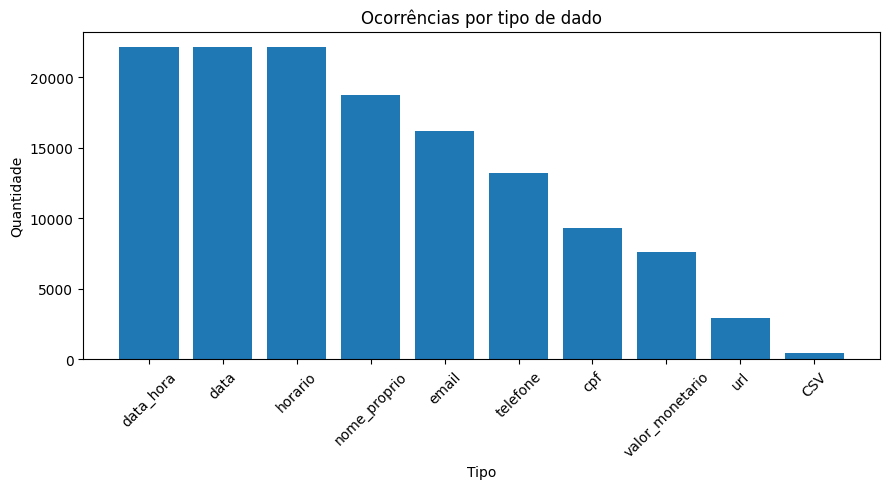

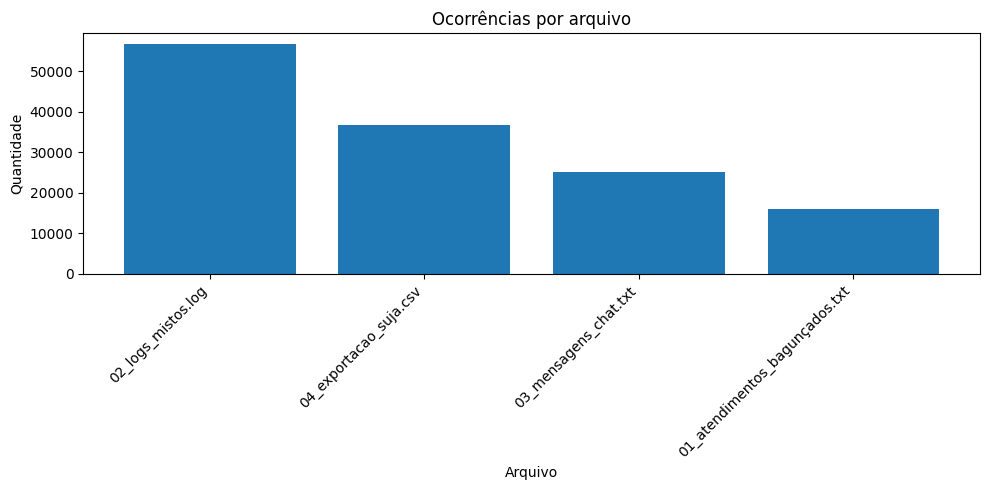

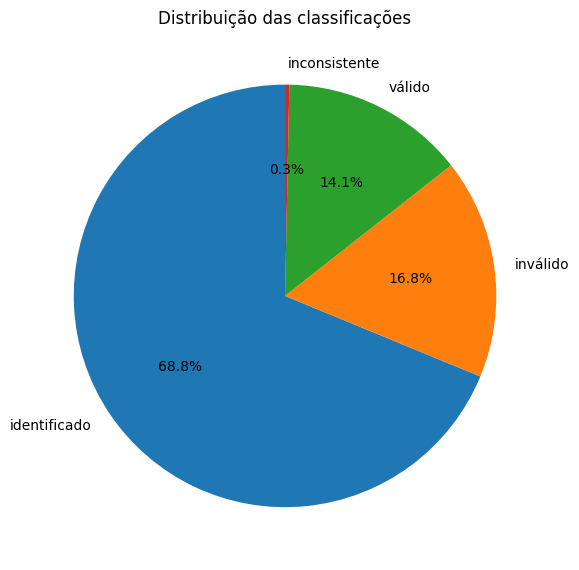

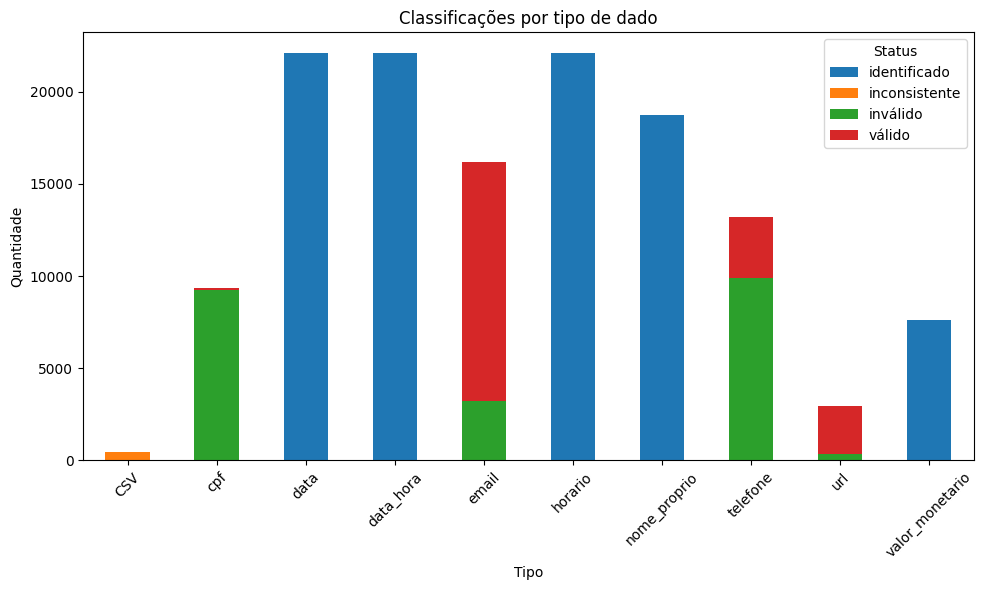

Relatório salvo em: /content/drive/MyDrive/Automatos regex trab/extraction/relatorio_resumo_questao_e.csv


In [130]:
import matplotlib.pyplot as plt

def carregarResultadosEstruturados(nome_arquivo=None):

    if nome_arquivo is None:
        nome_arquivo = os.path.join(filepath_extraction, "resultado_extracao.csv")
        
    # Usa a lista 'resultados' criada na questão D, se ela estiver disponível.
    if "resultados" in globals() and isinstance(resultados, list) and len(resultados) > 0:
        return pd.DataFrame(resultados)

    # Caso a célula D não esteja em memória, tenta carregar o CSV gerado por ela.
    if os.path.exists(nome_arquivo):
        return pd.read_csv(nome_arquivo)

    raise FileNotFoundError(
        "Execute primeiro as questões C e D, ou gere o arquivo resultado_extracao.csv."
    )


def normalizarStatus(classificacao):
    # Normaliza os textos de classificação para facilitar os agrupamentos do relatório.
    texto = str(classificacao).lower()

    if "inconsistência" in texto:
        return "inconsistente"

    if "inválid" in texto:
        return "inválido"

    if "válid" in texto:
        return "válido"

    if "padrão identificado" in texto:
        return "identificado"

    return "outro"


df_resultados = carregarResultadosEstruturados()

# Cria uma coluna auxiliar apenas para o relatório.
df_resultados["status"] = df_resultados["classificacao"].apply(normalizarStatus)

print("====================== RELATÓRIO FINAL ======================")
print(f"Total de ocorrências estruturadas: {len(df_resultados)}")
print(" ")

# Tabelas-resumo
resumo_tipo = (
    df_resultados
    .groupby("tipo")
    .size()
    .reset_index(name="quantidade")
    .sort_values("quantidade", ascending=False)
)

resumo_arquivo = (
    df_resultados
    .groupby("arquivo")
    .size()
    .reset_index(name="quantidade")
    .sort_values("quantidade", ascending=False)
)

resumo_status = (
    df_resultados
    .groupby("status")
    .size()
    .reset_index(name="quantidade")
    .sort_values("quantidade", ascending=False)
)

resumo_tipo_status = (
    df_resultados
    .groupby(["tipo", "status"])
    .size()
    .reset_index(name="quantidade")
)

print("Ocorrências por tipo:")
display(resumo_tipo)

print("Ocorrências por arquivo:")
display(resumo_arquivo)

print("Classificações por status:")
display(resumo_status)

print("Classificações por tipo:")
display(
    pd.crosstab(
        df_resultados["tipo"],
        df_resultados["status"],
        margins=True,
        margins_name="Total"
    )
)

print("Exemplos de ocorrências inválidas ou inconsistentes:")
display(
    df_resultados[df_resultados["status"].isin(["inválido", "inconsistente"])]
    .head(20)
)

# Gráfico 1: ocorrências por tipo
plt.figure(figsize=(9, 5))
plt.bar(resumo_tipo["tipo"], resumo_tipo["quantidade"])
plt.title("Ocorrências por tipo de dado")
plt.xlabel("Tipo")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico 2: ocorrências por arquivo
plt.figure(figsize=(10, 5))
plt.bar(resumo_arquivo["arquivo"], resumo_arquivo["quantidade"])
plt.title("Ocorrências por arquivo")
plt.xlabel("Arquivo")
plt.ylabel("Quantidade")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Gráfico 3: proporção de válidos, inválidos e inconsistentes
plt.figure(figsize=(6, 6))
plt.pie(
    resumo_status["quantidade"],
    labels=resumo_status["status"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribuição das classificações")
plt.tight_layout()
plt.show()

# Gráfico 4: status por tipo de dado
tabela_tipo_status = pd.crosstab(df_resultados["tipo"], df_resultados["status"])

tabela_tipo_status.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Classificações por tipo de dado")
plt.xlabel("Tipo")
plt.ylabel("Quantidade")
plt.xticks(rotation=45)
plt.legend(title="Status")
plt.tight_layout()
plt.show()

arquivo_relatorio_e = os.path.join(
    filepath_extraction,
    "relatorio_resumo_questao_e.csv"
)

resumo_tipo_status.to_csv(
    arquivo_relatorio_e,
    index=False,
    encoding="utf-8"
)

print(f"Relatório salvo em: {arquivo_relatorio_e}")